# Análisis exploratorio inicial: Inside Airbnb – Buenos Aires

**Materia:** Fundamentos de la Ciencia de Datos
**Archivos:** `listings.csv` (un registro por publicación) y `calendar.csv` (un registro por publicación y día).

Estructura (sigue el enunciado):
1. Origen de los datos
2. Caracterización de los atributos
3. Valores nulos
4. Distribución de variables y outliers
5. Calendario (`calendar.csv`)
6. Conclusiones, limitaciones y próximos pasos

> Para correrlo: poné `listings.csv` y `calendar.csv` en la misma carpeta que el notebook (o definí la variable de entorno `DATA_DIR`).

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

DATA_DIR = os.environ.get("DATA_DIR", ".")
pd.set_option("display.width", 160, "display.max_columns", 60, "display.float_format", "{:,.2f}".format)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100

## 1. Origen de los datos

**Fuente probable: [Inside Airbnb](https://insideairbnb.com/get-the-data/)**, un proyecto independiente que publica datos
obtenidos por *scraping* del sitio público de Airbnb. Las pistas que lo indican:

- Los nombres de archivo y de columnas (`listings.csv`, `calendar.csv`, `scrape_id`, `last_scraped`, `source`, `calculated_host_listings_count`…) coinciden con el diccionario de datos de Inside Airbnb.
- Los datos son de **Buenos Aires** (coordenadas, barrios como Palermo, Recoleta, San Nicolás) y los precios están en **pesos argentinos (ARS)**.
- Las fechas de scrape son de fines de junio / principios de julio de 2026 (se verifica abajo).

**Qué hay que tener presente sobre esta fuente (investigado online):**

- **No son datos oficiales de Airbnb.** Inside Airbnb aclara en su página de *Data Assumptions* que la exactitud de la información tomada del sitio de Airbnb no es su responsabilidad.
- Proveen un **modelo de ocupación ("San Francisco Model")** que estima reservas a partir de reseñas, usando una tasa de reseña del 50 % y una estadía promedio (en la documentación, 5,5 noches para San Francisco). Las columnas `estimated_occupancy_l365d` y `estimated_revenue_l365d` salen de ese tipo de modelo: **son estimaciones, no reservas reales**.
- Hay literatura que documentó **inconsistencias en el conteo de reseñas** de Inside Airbnb (ver *"Incorrect Data in the Widely Used Inside Airbnb Dataset"*, arXiv 2007.03019), así que conviene tomar `number_of_reviews` con cautela.
- Es una **foto puntual**: describe la oferta publicada en esos días, no la evolución en el tiempo.

Referencias: insideairbnb.com/data-assumptions, insideairbnb.com/get-the-data, arXiv:2007.03019.

In [3]:
listings = pd.read_csv(f"{DATA_DIR}/dataset/listings.csv")
print("listings:", listings.shape)
print("\nFechas de scrape (last_scraped):")
print(listings["last_scraped"].value_counts().sort_index())
print("\nscrape_id únicos:", listings["scrape_id"].unique())
print("\nsource:")
print(listings["source"].value_counts())
print("\nIDs duplicados:", listings["id"].duplicated().sum())
print("Hosts únicos:", listings["host_id"].nunique())

listings: (29685, 90)

Fechas de scrape (last_scraped):
last_scraped
2026-06-29     9278
2026-06-30     2560
2026-07-01     4834
2026-07-02    13013
Name: count, dtype: int64

scrape_id únicos: [20260629030533]

source:
source
city scrape        27682
previous scrape     2003
Name: count, dtype: int64

IDs duplicados: 0
Hosts únicos: 14556


## 2. Caracterización de los atributos

El archivo tiene **90 columnas**, más que las del diccionario v4.3 que nos pasaron (agosto 2022). Hay columnas nuevas que
el diccionario no documenta, y `source` ahora toma el valor `city scrape` (en el diccionario figuraba `neighbourhood search`).
Esto indica que **el diccionario está desactualizado respecto del archivo**.

In [4]:
nuevas = ["host_profile_id","host_profile_url","hosts_time_as_user_years","hosts_time_as_user_months",
          "hosts_time_as_host_years","hosts_time_as_host_months","price_quote_checkin_date",
          "price_quote_checkout_date","price_quote_total_price","price_quote_price_per_night","price_quote_raw",
          "availability_eoy","number_of_reviews_ly","estimated_occupancy_l365d","estimated_revenue_l365d"]
print("Columnas del archivo NO presentes en el diccionario v4.3:")
listings[nuevas].dtypes.to_frame("dtype")

Columnas del archivo NO presentes en el diccionario v4.3:


,dtype
host_profile_id,int64
host_profile_url,str
hosts_time_as_user_years,int64
hosts_time_as_user_months,int64
hosts_time_as_host_years,int64
hosts_time_as_host_months,int64
price_quote_checkin_date,str
price_quote_checkout_date,str
price_quote_total_price,float64
price_quote_price_per_night,float64


In [5]:
# Clasificación de variables por tipo (según su naturaleza, no solo el dtype que infiere pandas)
urls = [c for c in listings if c.endswith("_url")]
fechas = ["last_scraped","calendar_last_scraped","first_review","last_review","price_quote_checkin_date",
          "price_quote_checkout_date","host_since"]
booleanas = ["host_is_superhost","host_has_profile_pic","host_identity_verified","has_availability","instant_bookable"]
texto = ["name","description","neighborhood_overview","host_about","host_location","amenities","bathrooms_text",
         "price","price_quote_raw","license","host_name"]
ids = ["id","scrape_id","host_id","host_profile_id"]
categoricas = ["source","room_type","property_type","neighbourhood_cleansed","host_response_time"]
usadas = set(urls+fechas+booleanas+texto+ids+categoricas)
numericas = [c for c in listings.select_dtypes("number").columns if c not in usadas and listings[c].notna().any()]

resumen = pd.Series({"identificadores":len(ids),"URLs":len(urls),"fechas":len(fechas),"booleanas":len(booleanas),
                     "texto libre / semiestructurado":len(texto),"categóricas":len(categoricas),
                     "numéricas":len(numericas)}, name="cantidad")
display(resumen.to_frame())
print("Numéricas (con al menos un dato):", numericas)

,cantidad
identificadores,4
URLs,6
fechas,7
booleanas,5
texto libre / semiestructurado,11
categóricas,5
numéricas,44


Numéricas (con al menos un dato): ['hosts_time_as_user_years', 'hosts_time_as_user_months', 'hosts_time_as_host_years', 'hosts_time_as_host_months', 'host_listings_count', 'latitude', 'longitude', 'accommodates', 'bathrooms', 'bedrooms', 'beds', 'price_quote_total_price', 'price_quote_price_per_night', 'minimum_nights', 'maximum_nights', 'minimum_minimum_nights', 'maximum_minimum_nights', 'minimum_maximum_nights', 'maximum_maximum_nights', 'minimum_nights_avg_ntm', 'maximum_nights_avg_ntm', 'availability_30', 'availability_60', 'availability_90', 'availability_365', 'number_of_reviews', 'number_of_reviews_ltm', 'number_of_reviews_l30d', 'availability_eoy', 'number_of_reviews_ly', 'estimated_occupancy_l365d', 'estimated_revenue_l365d', 'review_scores_rating', 'review_scores_accuracy', 'review_scores_cleanliness', 'review_scores_checkin', 'review_scores_communication', 'review_scores_location', 'review_scores_value', 'calculated_host_listings_count', 'calculated_host_listings_count_entir

## 3. Valores nulos

In [6]:
nulos = listings.isna().mean().sort_values(ascending=False)
tabla_nulos = pd.DataFrame({"% nulos": nulos*100, "n nulos": listings.isna().sum()[nulos.index]})
solo_vacias = tabla_nulos[tabla_nulos["% nulos"]==100]
print(f"Columnas 100% vacías: {len(solo_vacias)}")
print(list(solo_vacias.index))
print()
display(tabla_nulos[(tabla_nulos["% nulos"]>0)&(tabla_nulos["% nulos"]<100)].head(25))

Columnas 100% vacías: 13
['neighborhood_overview', 'host_since', 'host_response_time', 'host_thumbnail_url', 'host_acceptance_rate', 'host_response_rate', 'host_verifications', 'neighbourhood', 'host_total_listings_count', 'host_neighbourhood', 'calendar_updated', 'instant_bookable', 'neighbourhood_group_cleansed']



,% nulos,n nulos
license,98.36,29199
host_about,43.58,12938
host_location,22.17,6580
bedrooms,17.47,5185
review_scores_cleanliness,12.56,3728
review_scores_accuracy,12.56,3728
first_review,12.56,3728
review_scores_checkin,12.56,3728
review_scores_rating,12.56,3728
reviews_per_month,12.56,3728


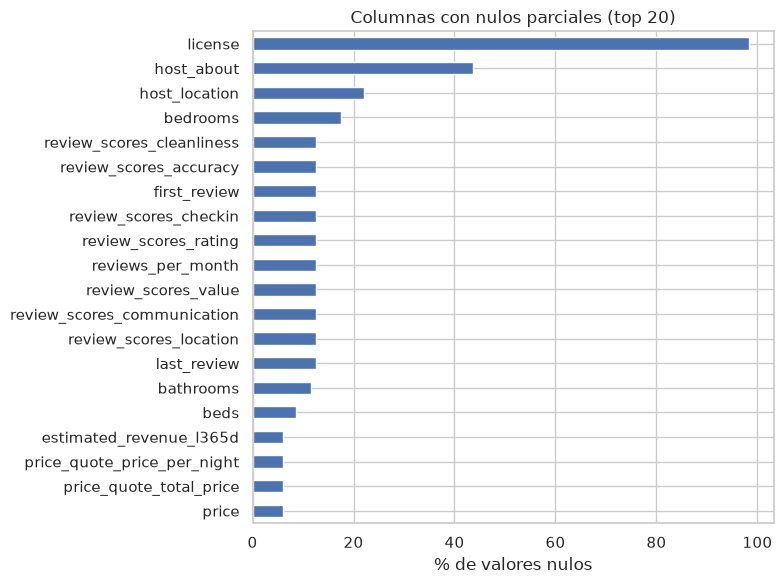

In [7]:
parciales = tabla_nulos[(tabla_nulos["% nulos"]>0)&(tabla_nulos["% nulos"]<100)].head(20)
fig, ax = plt.subplots(figsize=(8,6))
parciales["% nulos"][::-1].plot.barh(ax=ax, color="#4c72b0")
ax.set_xlabel("% de valores nulos"); ax.set_title("Columnas con nulos parciales (top 20)")
plt.tight_layout(); plt.show()

**Lectura de los nulos**

- **Columnas 100 % vacías:** (listadas arriba) incluyen `host_since`, `host_response_time`, `host_response_rate`, `host_acceptance_rate`, `neighbourhood`, `neighbourhood_group_cleansed`, `instant_bookable`, `calendar_updated`, entre otras. Parecen **campos que el scraping actual ya no completa**, no ausencia real de información. No aportan nada al análisis y se descartan.
- **`license` (~98 % nulo):** la mayoría de las publicaciones no declara número de licencia/registro.
- **Reseñas (~12,6 % nulo, todas juntas):** `review_scores_*`, `first_review`, `last_review` y `reviews_per_month` son nulas **exactamente en las publicaciones sin reseñas**. Es un nulo estructural (no es un error), y hay que decidir cómo tratarlo según el análisis.
- **`price` (~6 % nulo):** se debe decidir si se descartan o se imputan; no conviene imputar con la media por los outliers.
- **`bedrooms` (~17,5 %), `bathrooms` (~11,6 %), `beds` (~8,7 %):** nulos relevantes en variables estructurales.

In [7]:
# Verificación: los nulos de reseñas coinciden con number_of_reviews == 0
sin_resenas = listings["number_of_reviews"] == 0
print("Publicaciones sin reseñas:", sin_resenas.sum(), f"({sin_resenas.mean():.1%})")
print("Nulos en review_scores_rating:", listings["review_scores_rating"].isna().sum())
print("¿Coinciden?", (listings["review_scores_rating"].isna() == sin_resenas).mean())

Publicaciones sin reseñas: 3728 (12.6%)
Nulos en review_scores_rating: 3728
¿Coinciden? 1.0


## 4. Limpieza mínima y distribución de variables
Convertimos `price` a número (viene como texto con `$` y comas; el `$` es un artefacto del export y la moneda es ARS),
pasamos `t/f` a booleano y las fechas a `datetime`. Descartamos las columnas 100 % vacías.

In [8]:
df = listings.drop(columns=list(solo_vacias.index)).copy()
df["price"] = df["price"].str.replace(r"[\$,]", "", regex=True).astype(float)
for c in ["host_is_superhost","host_has_profile_pic","host_identity_verified","has_availability"]:
    df[c] = df[c].map({"t": True, "f": False})
for c in ["last_scraped","calendar_last_scraped","first_review","last_review"]:
    df[c] = pd.to_datetime(df[c])
df["log_price"] = np.log10(df["price"])
print(df.shape)

(29685, 78)


In [9]:
cols_num = ["price","accommodates","bedrooms","beds","bathrooms","minimum_nights","maximum_nights",
            "availability_365","number_of_reviews","reviews_per_month","review_scores_rating",
            "calculated_host_listings_count","estimated_occupancy_l365d","estimated_revenue_l365d"]
desc = df[cols_num].describe(percentiles=[.01,.25,.5,.75,.99]).T
desc["skew"] = df[cols_num].skew()
desc

,count,mean,std,min,1%,25%,50%,75%,99%,max,skew
price,"27,893.00","275,831.94","3,622,301.98","1,215.50","22,448.72","75,274.57","100,631.33","140,480.93","811,997.61","171,643,781.00",29.37
accommodates,"29,685.00",2.94,1.58,1.00,1.00,2.00,2.00,4.00,8.16,16.00,3.09
bedrooms,"24,500.00",1.35,0.91,0.00,1.00,1.00,1.00,1.00,4.00,31.00,7.89
beds,"27,102.00",1.95,1.62,1.00,1.00,1.00,1.00,2.00,7.00,50.00,6.87
bathrooms,"26,244.00",1.24,0.70,0.50,1.00,1.00,1.00,1.00,4.00,22.00,7.71
minimum_nights,"29,682.00",4.95,18.11,1.00,1.00,1.00,2.00,3.00,50.00,730.00,16.73
maximum_nights,"29,682.00",563.33,430.72,1.00,7.00,364.00,365.00,"1,125.00","1,125.00","3,659.00",0.43
availability_365,"29,685.00",235.02,116.16,0.00,0.00,148.00,264.00,343.00,365.00,365.00,-0.57
number_of_reviews,"29,685.00",39.84,59.24,0.00,0.00,3.00,17.00,53.00,279.16,"1,106.00",3.23
reviews_per_month,"25,957.00",1.48,1.64,0.01,0.03,0.37,0.98,2.05,7.65,41.66,3.34


In [9]:
vacias = listings.columns[listings.isna().all()]
print(len(vacias), "columnas vacías:")
print(list(vacias))
nulos = (listings.isna().mean() * 100).sort_values(ascending=False)
nulos[nulos == 100]

13 columnas vacías:
['neighborhood_overview', 'host_since', 'host_response_time', 'host_response_rate', 'host_acceptance_rate', 'host_thumbnail_url', 'host_neighbourhood', 'host_total_listings_count', 'host_verifications', 'neighbourhood', 'neighbourhood_group_cleansed', 'calendar_updated', 'instant_bookable']


neighborhood_overview          100.00
host_since                     100.00
host_response_time             100.00
host_thumbnail_url             100.00
host_acceptance_rate           100.00
host_response_rate             100.00
host_verifications             100.00
neighbourhood                  100.00
host_total_listings_count      100.00
host_neighbourhood             100.00
calendar_updated               100.00
instant_bookable               100.00
neighbourhood_group_cleansed   100.00
dtype: float64

### 4.1 Precio (ARS por noche)

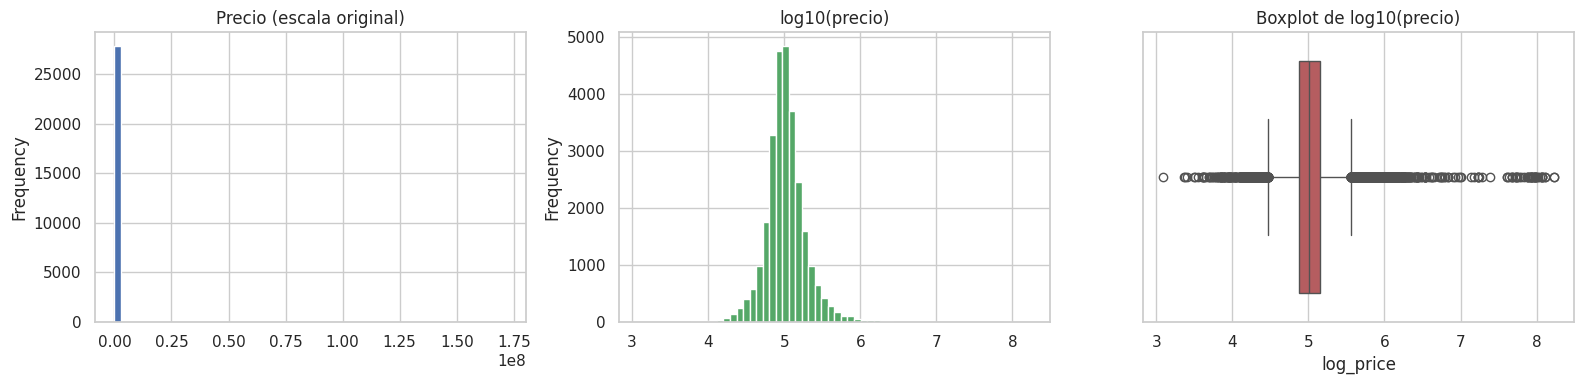

count        27,893.00
mean        275,832.00
std       3,622,302.00
min           1,216.00
1%           22,449.00
5%           41,211.00
50%         100,631.00
95%         305,386.00
99%         811,998.00
max     171,643,781.00
Name: price, dtype: float64

Media / mediana = 2.74  -> distribución muy asimétrica a la derecha


In [10]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
df["price"].dropna().plot.hist(bins=60, ax=ax[0], color="#4c72b0"); ax[0].set_title("Precio (escala original)")
df["log_price"].dropna().plot.hist(bins=60, ax=ax[1], color="#55a868"); ax[1].set_title("log10(precio)")
sns.boxplot(x=df["log_price"], ax=ax[2], color="#c44e52"); ax[2].set_title("Boxplot de log10(precio)")
plt.tight_layout(); plt.show()

p = df["price"].dropna()
print(p.describe(percentiles=[.01,.05,.5,.95,.99]).round(0))
print(f"\nMedia / mediana = {p.mean()/p.median():.2f}  -> distribución muy asimétrica a la derecha")

In [11]:
# Outliers por regla IQR (sobre log10 del precio, porque en escala original la regla marca demasiado)
q1, q3 = df["log_price"].quantile([.25, .75]); iqr = q3 - q1
lo, hi = q1 - 1.5*iqr, q3 + 1.5*iqr
out_hi = df[df["log_price"] > hi]; out_lo = df[df["log_price"] < lo]
print(f"Límites IQR (en ARS): {10**lo:,.0f}  a  {10**hi:,.0f}")
print(f"Outliers altos: {len(out_hi)} | bajos: {len(out_lo)}")
print(f"Precios > 1.000.000 ARS/noche: {(df['price']>1e6).sum()}")
print("\nLos 10 precios más altos:")
df.nlargest(10, "price")[["id","name","room_type","accommodates","price","minimum_nights","number_of_reviews"]]

Límites IQR (en ARS): 29,525  a  358,155
Outliers altos: 1021 | bajos: 622
Precios > 1.000.000 ARS/noche: 214

Los 10 precios más altos:


,id,name,room_type,accommodates,price,minimum_nights,number_of_reviews
22904,1129061456278584353,Disfruta de un espacio luminoso en Bs As.,Entire home/apt,2,"171,643,781.00",1.00,2
3326,1048051998916469708,Habitación espaciosa,Private room,1,"169,983,305.00",2.00,0
24259,1554424397955633364,Relax Jardines,Entire home/apt,3,"129,721,451.00",1.00,35
16530,568616064324992190,Hermosa habitación en casa de estilo Inglés,Private room,1,"128,501,556.00",5.00,1
717,1693690429819868240,departamento en palermo,Entire home/apt,2,"119,163,498.40",1.00,0
24799,1693702447946194916,departamento palermo,Entire home/apt,4,"119,163,498.40",1.00,0
1704,1593615287549421619,Tu estadia en Villa Crespo,Entire home/apt,4,"118,540,097.00",1.00,0
25184,1171679736496714320,"Apartamento en Palermo, CASA REINA",Entire home/apt,2,"117,971,864.00",1.00,0
24034,1099478715504968920,departamento completo,Entire home/apt,3,"110,269,755.00",1.00,0
24281,1715206674581824021,Departamento completo,Entire home/apt,4,"103,854,017.50",2.00,0


**Lectura del precio**

- Media mucho mayor que la mediana (≈ 276 mil vs ≈ 101 mil ARS): **fuerte asimetría a la derecha**, por lo que la media no es representativa. Conviene trabajar con **mediana o con `log(precio)`**.
- Hay valores extremos (máximo ≈ 171 millones de ARS por noche). Los 10 más altos son departamentos y habitaciones comunes, casi todos **sin reseñas o con muy pocas**, con títulos corrientes: parecen **precios mal cargados o valores "placeholder"**, no oferta real. Hay 214 publicaciones por encima de 1 millón de ARS/noche. Hay que decidir un criterio de exclusión y justificarlo.
- Los precios están en **pesos argentinos**: con inflación alta, la comparación temporal con otros scrapes requeriría ajustar o convertir a USD.

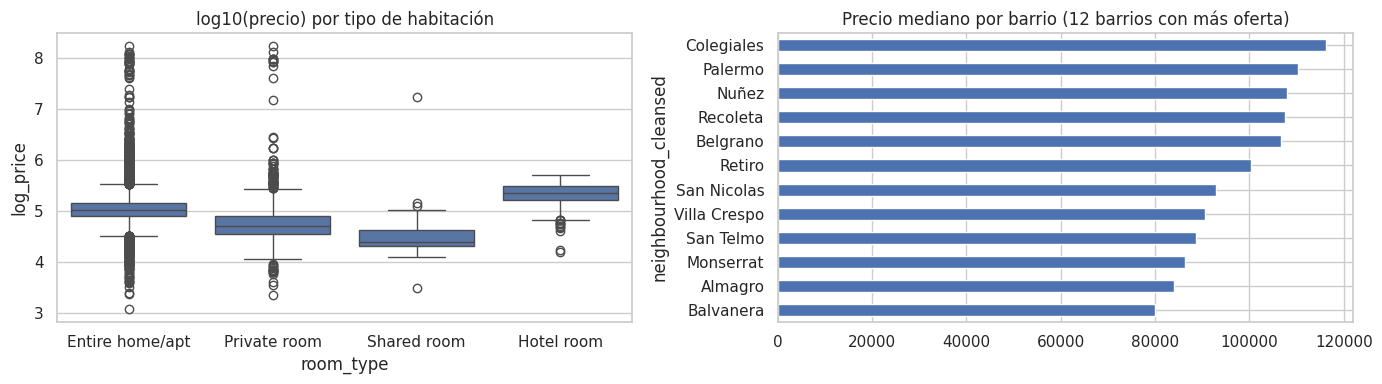

,count,median
room_type,,
Entire home/apt,25141,"103,977.00"
Hotel room,136,"222,895.50"
Private room,2485,"51,002.00"
Shared room,131,"25,405.00"


In [12]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
sns.boxplot(data=df, x="room_type", y="log_price", ax=ax[0]); ax[0].set_title("log10(precio) por tipo de habitación")
top = df["neighbourhood_cleansed"].value_counts().head(12).index
med = df[df["neighbourhood_cleansed"].isin(top)].groupby("neighbourhood_cleansed")["price"].median().sort_values()
med.plot.barh(ax=ax[1], color="#4c72b0"); ax[1].set_title("Precio mediano por barrio (12 barrios con más oferta)")
plt.tight_layout(); plt.show()
df.groupby("room_type")["price"].agg(["count","median"])

### 4.2 Variables categóricas

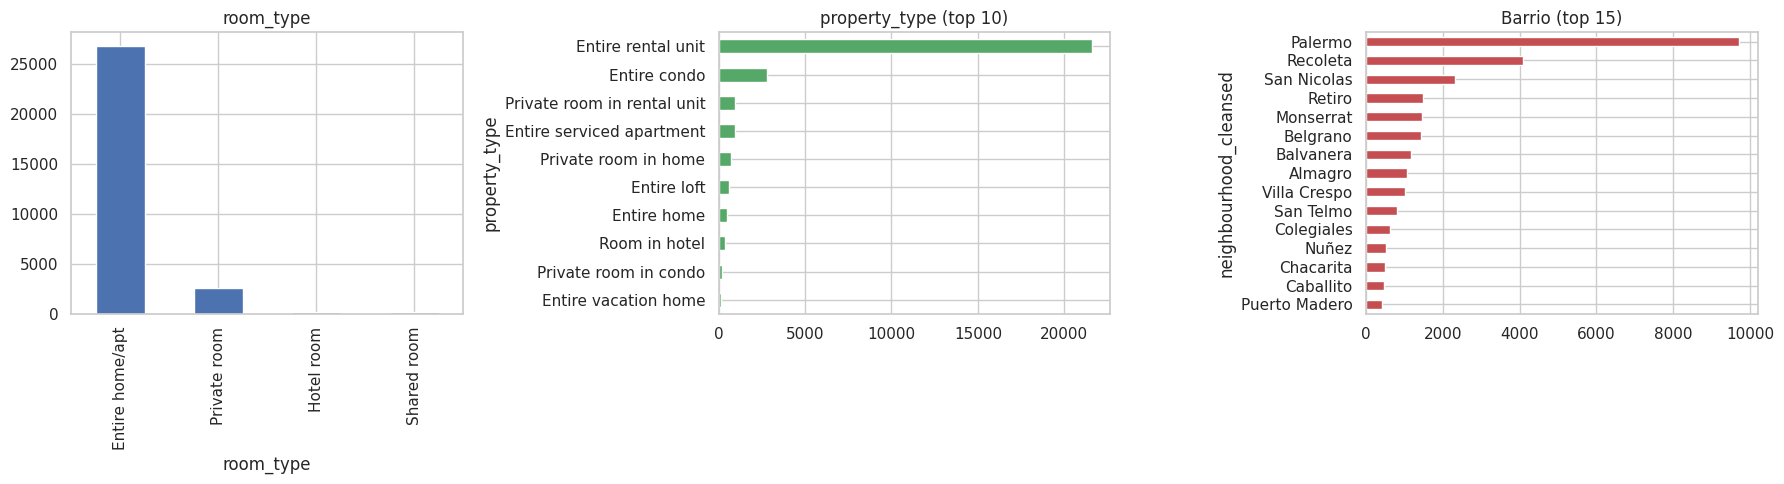

Barrios distintos: 48 | tipos de propiedad distintos: 56

% por room_type:
room_type
Entire home/apt   90.20
Private room       8.80
Hotel room         0.50
Shared room        0.50
Name: proportion, dtype: float64

Concentración: Palermo + Recoleta = 46.5% de la oferta


In [13]:
fig, ax = plt.subplots(1, 3, figsize=(18, 5))
df["room_type"].value_counts().plot.bar(ax=ax[0], color="#4c72b0"); ax[0].set_title("room_type")
df["property_type"].value_counts().head(10).plot.barh(ax=ax[1], color="#55a868"); ax[1].invert_yaxis(); ax[1].set_title("property_type (top 10)")
df["neighbourhood_cleansed"].value_counts().head(15).plot.barh(ax=ax[2], color="#c44e52"); ax[2].invert_yaxis(); ax[2].set_title("Barrio (top 15)")
plt.tight_layout(); plt.show()

print("Barrios distintos:", df["neighbourhood_cleansed"].nunique(), "| tipos de propiedad distintos:", df["property_type"].nunique())
print("\n% por room_type:"); print((df["room_type"].value_counts(normalize=True)*100).round(1))
print("\nConcentración: Palermo + Recoleta =", f"{df['neighbourhood_cleansed'].isin(['Palermo','Recoleta']).mean():.1%}", "de la oferta")

### 4.3 Capacidad y estructura de la propiedad

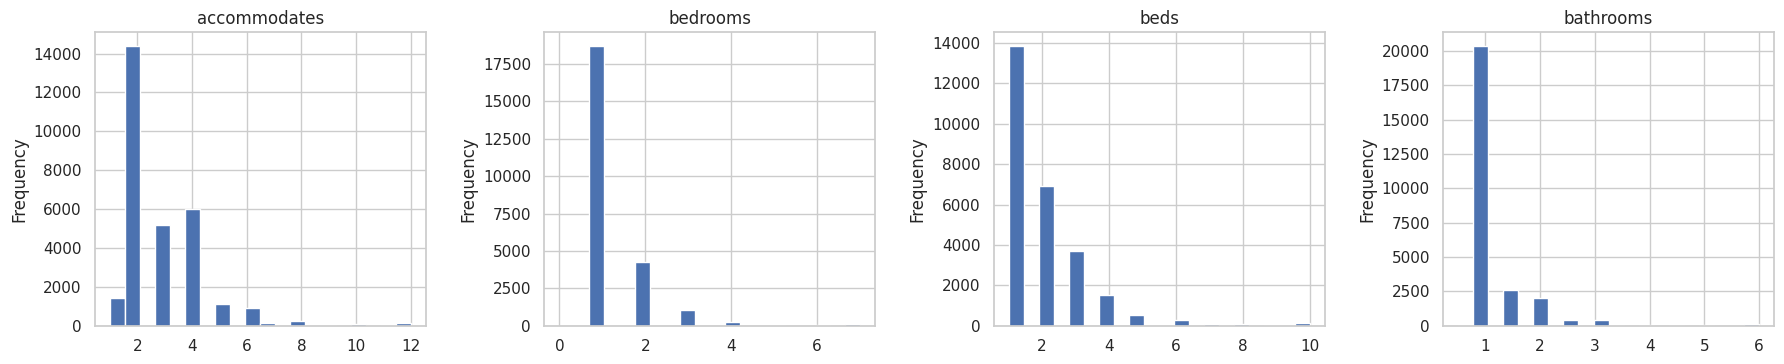

Casos extremos:
bedrooms >= 10: 35 | bathrooms >= 8: 43 | beds >= 20: 28
Casos de bedrooms = 0 (estudios/monoambientes): 4


In [14]:
fig, ax = plt.subplots(1, 4, figsize=(18, 3.8))
for a, c in zip(ax, ["accommodates","bedrooms","beds","bathrooms"]):
    df[c].dropna().clip(upper=df[c].quantile(.995)).plot.hist(bins=20, ax=a, color="#4c72b0"); a.set_title(c)
plt.tight_layout(); plt.show()

print("Casos extremos:")
print("bedrooms >= 10:", (df['bedrooms']>=10).sum(), "| bathrooms >= 8:", (df['bathrooms']>=8).sum(), "| beds >= 20:", (df['beds']>=20).sum())
print("Casos de bedrooms = 0 (estudios/monoambientes):", (df['bedrooms']==0).sum())

### 4.4 Reglas de estadía (`minimum_nights` / `maximum_nights`)

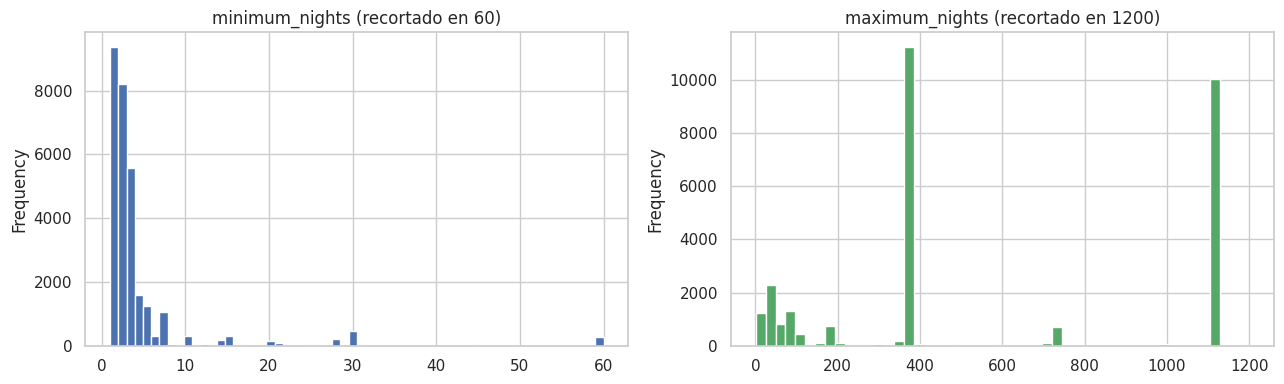

minimum_nights > 30 (alquiler de mediana/larga estadía): 1.2%
minimum_nights máx: 730.0 | maximum_nights máx: 3659.0
maximum_nights == 1125 (valor 'por defecto' de Airbnb): 33.7%


In [15]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
df["minimum_nights"].clip(upper=60).plot.hist(bins=60, ax=ax[0], color="#4c72b0"); ax[0].set_title("minimum_nights (recortado en 60)")
df["maximum_nights"].clip(upper=1200).plot.hist(bins=50, ax=ax[1], color="#55a868"); ax[1].set_title("maximum_nights (recortado en 1200)")
plt.tight_layout(); plt.show()
print("minimum_nights > 30 (alquiler de mediana/larga estadía):", f"{(df['minimum_nights']>30).mean():.1%}")
print("minimum_nights máx:", df["minimum_nights"].max(), "| maximum_nights máx:", df["maximum_nights"].max())
print("maximum_nights == 1125 (valor 'por defecto' de Airbnb):", f"{(df['maximum_nights']==1125).mean():.1%}")

### 4.5 Reseñas y puntajes

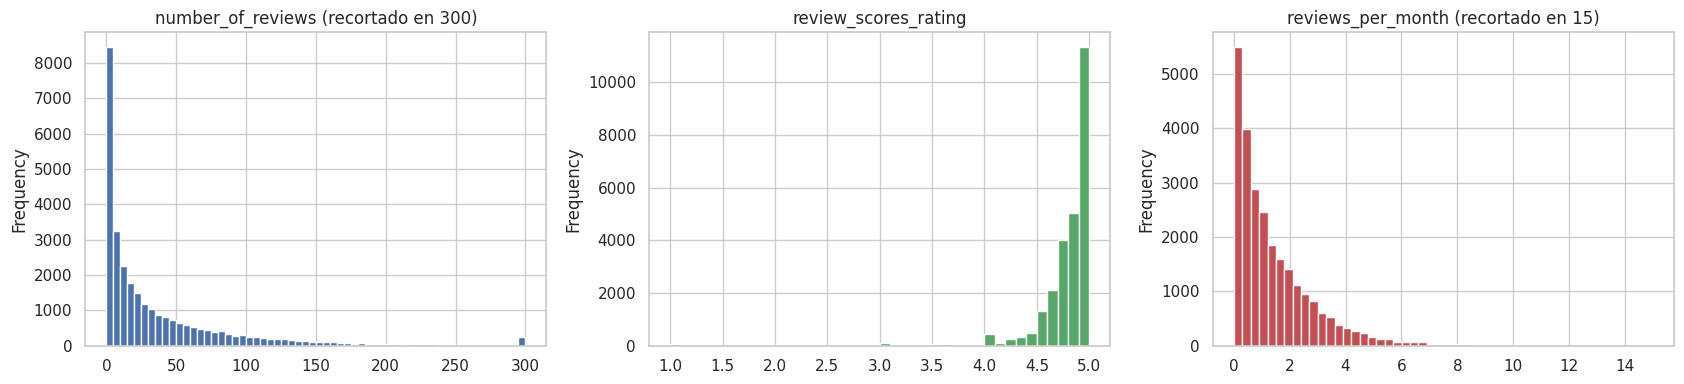

count   25,957.00
mean         4.78
std          0.36
min          1.00
25%          4.73
50%          4.87
75%          4.98
max          5.00
Name: review_scores_rating, dtype: float64

% con puntaje >= 4.5: 91.7% (sobre los que tienen puntaje)


In [16]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
df["number_of_reviews"].clip(upper=300).plot.hist(bins=60, ax=ax[0], color="#4c72b0"); ax[0].set_title("number_of_reviews (recortado en 300)")
df["review_scores_rating"].dropna().plot.hist(bins=40, ax=ax[1], color="#55a868"); ax[1].set_title("review_scores_rating")
df["reviews_per_month"].dropna().clip(upper=15).plot.hist(bins=50, ax=ax[2], color="#c44e52"); ax[2].set_title("reviews_per_month (recortado en 15)")
plt.tight_layout(); plt.show()

print(df["review_scores_rating"].describe().round(2))
print(f"\n% con puntaje >= 4.5: {(df['review_scores_rating']>=4.5).sum()/df['review_scores_rating'].notna().sum():.1%} (sobre los que tienen puntaje)")

**Lectura:** el puntaje está **fuertemente concentrado cerca de 5** (sesgo conocido de los sistemas de reseñas: casi todo es "excelente"), por lo que discrimina poco entre publicaciones. Y `number_of_reviews` tiene una cola larga: pocas publicaciones concentran muchas reseñas.

### 4.6 Hosts y concentración de la oferta

Hosts únicos: 14556 | publicaciones: 29685
Publicaciones por host - mediana: 1.0 | máx: 208
% de publicaciones de hosts con 2+ publicaciones: 63.6%
% de publicaciones de hosts con 10+ publicaciones: 28.3%
% de hosts que son Superhost (a nivel publicación): 41.1%


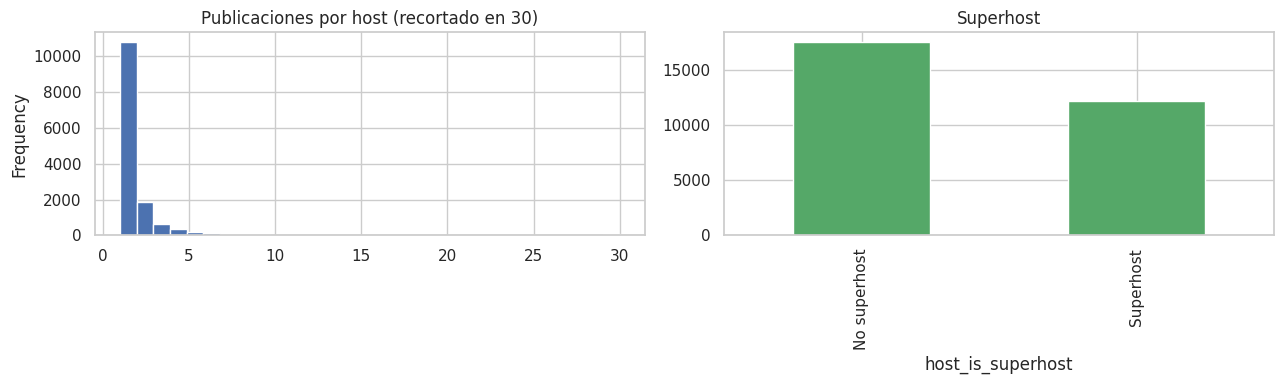

In [17]:
hosts = df.groupby("host_id").agg(n=("id","size"), listings_en_ciudad=("calculated_host_listings_count","max"))
print("Hosts únicos:", len(hosts), "| publicaciones:", len(df))
print("Publicaciones por host - mediana:", hosts["n"].median(), "| máx:", hosts["n"].max())
print(f"% de publicaciones de hosts con 2+ publicaciones: {(df['calculated_host_listings_count']>=2).mean():.1%}")
print(f"% de publicaciones de hosts con 10+ publicaciones: {(df['calculated_host_listings_count']>=10).mean():.1%}")
print(f"% de hosts que son Superhost (a nivel publicación): {df['host_is_superhost'].mean():.1%}")

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
hosts["n"].clip(upper=30).plot.hist(bins=30, ax=ax[0], color="#4c72b0"); ax[0].set_title("Publicaciones por host (recortado en 30)")
df["host_is_superhost"].value_counts().rename({True:"Superhost", False:"No superhost"}).plot.bar(ax=ax[1], color="#55a868"); ax[1].set_title("Superhost")
plt.tight_layout(); plt.show()

**Lectura:** hay ≈ 14,6 mil hosts para ≈ 29,7 mil publicaciones. La mediana es 1 publicación por host, pero **≈ 64 % de las publicaciones pertenece a hosts con 2 o más y ≈ 28 % a hosts con 10 o más** (el máximo es 208). Eso sugiere una **oferta muy profesionalizada**, no solo anfitriones particulares. Además, ≈ 41 % de las publicaciones son de Superhosts, un porcentaje alto que conviene tener presente al interpretar esa variable.

### 4.7 Disponibilidad y ocupación estimada

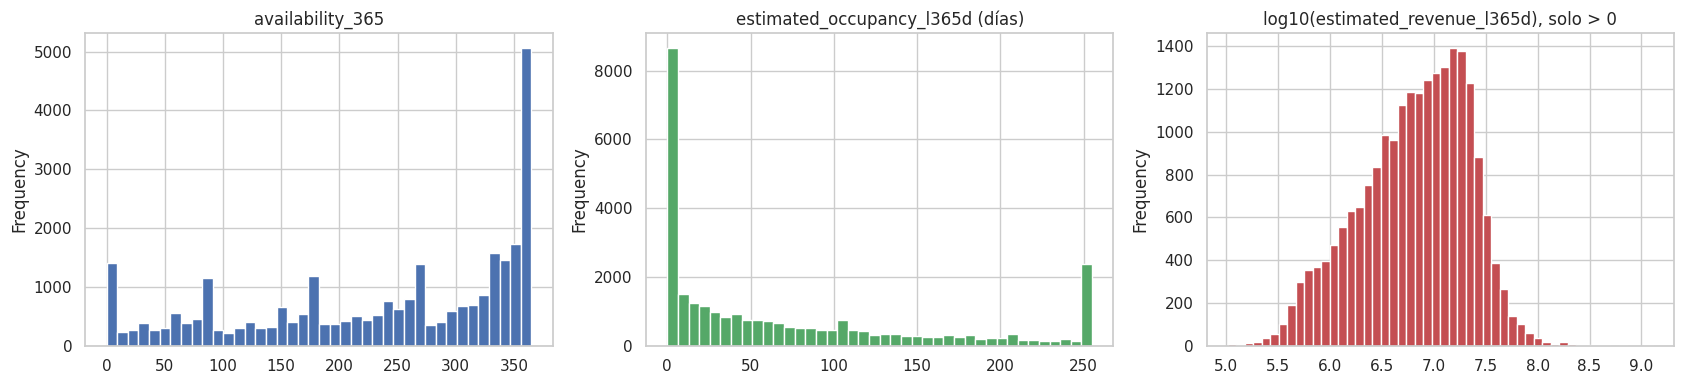

       availability_30  availability_90  availability_365  estimated_occupancy_l365d
count        29,685.00        29,685.00         29,685.00                  29,685.00
mean             13.80            55.80            235.00                      74.50
std              11.40            31.00            116.20                      82.60
min               0.00             0.00              0.00                       0.00
25%               2.00            32.00            148.00                       6.00
50%              13.00            64.00            264.00                      42.00
75%              26.00            84.00            343.00                     120.00
max              30.00            90.00            365.00                     255.00

Publicaciones con availability_365 == 0: 3.7% | con availability_365 == 365: 6.3%
Publicaciones con estimated_occupancy_l365d == 255 (tope del modelo?): 7.6%


In [18]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
df["availability_365"].plot.hist(bins=40, ax=ax[0], color="#4c72b0"); ax[0].set_title("availability_365")
df["estimated_occupancy_l365d"].plot.hist(bins=40, ax=ax[1], color="#55a868"); ax[1].set_title("estimated_occupancy_l365d (días)")
df.loc[df["estimated_revenue_l365d"]>0,"estimated_revenue_l365d"].pipe(np.log10).plot.hist(bins=50, ax=ax[2], color="#c44e52"); ax[2].set_title("log10(estimated_revenue_l365d), solo > 0")
plt.tight_layout(); plt.show()
print(df[["availability_30","availability_90","availability_365","estimated_occupancy_l365d"]].describe().round(1))
print("\nPublicaciones con availability_365 == 0:", f"{(df['availability_365']==0).mean():.1%}",
      "| con availability_365 == 365:", f"{(df['availability_365']==365).mean():.1%}")
print("Publicaciones con estimated_occupancy_l365d == 255 (tope del modelo?):", f"{(df['estimated_occupancy_l365d']==255).mean():.1%}")

**Lectura:** `availability_365` tiene mediana de 264 días, con picos chicos en 0 (≈ 3,7 %: calendario cerrado o todo reservado) y en 365 (≈ 6,3 %: calendario totalmente abierto). `estimated_occupancy_l365d` tiene un **máximo exacto de 255 días** (≈ 7,6 % de las publicaciones lo alcanza): es un **tope del modelo de estimación, no del mercado real**. Ojo: *disponibilidad ≠ ocupación*, porque un día no disponible puede estar bloqueado por el host.

### 4.8 Distribución espacial

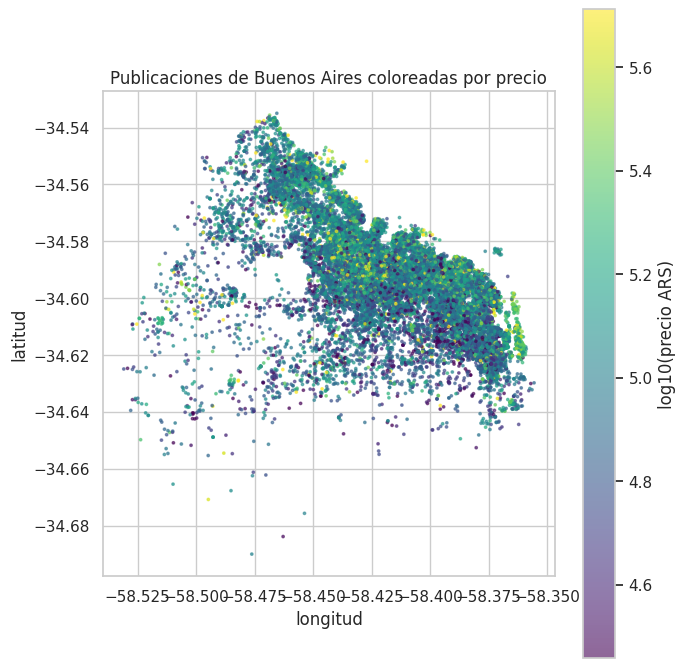

Rango latitud: -34.69 -34.535 | longitud: -58.531 -58.356


In [19]:
fig, ax = plt.subplots(figsize=(7, 7))
m = df.dropna(subset=["log_price"])
sc = ax.scatter(m["longitude"], m["latitude"], c=m["log_price"], s=3, cmap="viridis", alpha=.6,
                vmin=m["log_price"].quantile(.02), vmax=m["log_price"].quantile(.98))
plt.colorbar(sc, label="log10(precio ARS)"); ax.set_title("Publicaciones de Buenos Aires coloreadas por precio")
ax.set_xlabel("longitud"); ax.set_ylabel("latitud"); ax.set_aspect(1/np.cos(np.radians(34.6)))
plt.tight_layout(); plt.show()
print("Rango latitud:", df["latitude"].min().round(3), df["latitude"].max().round(3),
      "| longitud:", df["longitude"].min().round(3), df["longitude"].max().round(3))

### 4.9 Correlaciones

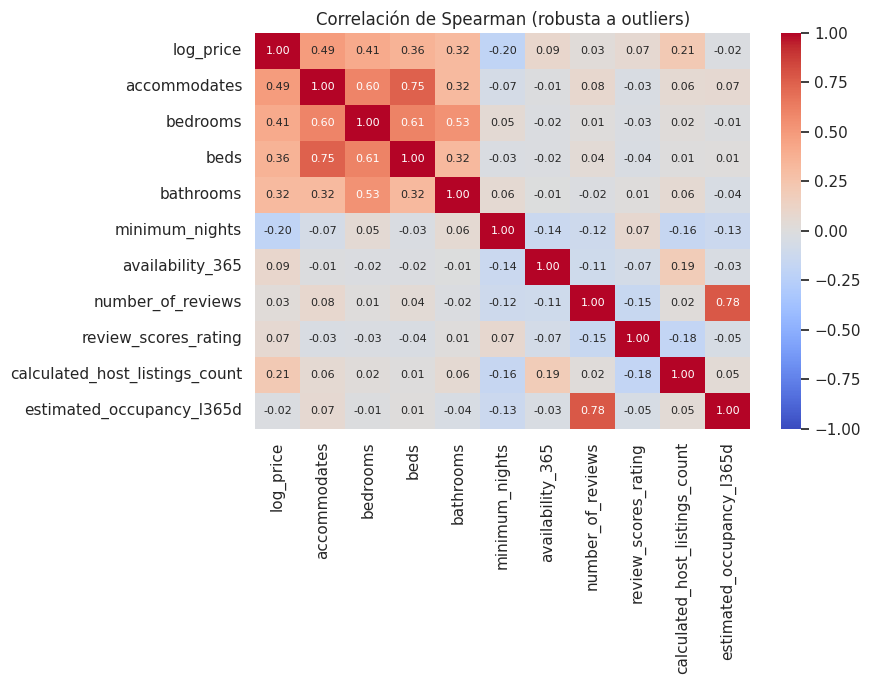

In [20]:
num_corr = ["log_price","accommodates","bedrooms","beds","bathrooms","minimum_nights","availability_365",
            "number_of_reviews","review_scores_rating","calculated_host_listings_count","estimated_occupancy_l365d"]
corr = df[num_corr].corr(method="spearman")
plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1, annot_kws={"size": 8})
plt.title("Correlación de Spearman (robusta a outliers)"); plt.tight_layout(); plt.show()

## 5. Calendario (`calendar.csv`)

Una fila por publicación y día, 365 días hacia adelante desde la fecha del scrape. **Ojo:** este calendario **no trae precio por día** (no tiene `price` ni `adjusted_price`), solo disponibilidad y las reglas de noches mínimas/máximas. El precio sale únicamente de `listings.csv`.

In [21]:
cal = pd.read_csv(f"{DATA_DIR}/calendar.csv",
                  dtype={"listing_id":"int64","available":"category","minimum_nights":"int32","maximum_nights":"int32"},
                  parse_dates=["date"])
print("calendar:", cal.shape, f"| memoria ≈ {cal.memory_usage(deep=True).sum()/1e6:.0f} MB")
print("Rango de fechas:", cal["date"].min().date(), "->", cal["date"].max().date())
print("Publicaciones distintas:", cal["listing_id"].nunique())
print("Nulos:", cal.isna().sum().to_dict())
print("Duplicados (listing_id, date):", cal.duplicated(["listing_id","date"]).sum())
dias = cal.groupby("listing_id").size()
print("Días por publicación:", dias.value_counts().to_dict())
print("IDs del calendario que no están en listings:", len(set(cal["listing_id"]) - set(listings["id"])),
      "| IDs de listings sin calendario:", len(set(listings["id"]) - set(cal["listing_id"])))

calendar: (10835026, 5) | memoria ≈ 271 MB
Rango de fechas: 2026-06-29 -> 2027-07-01
Publicaciones distintas: 29685
Nulos: {'listing_id': 0, 'date': 0, 'available': 0, 'minimum_nights': 0, 'maximum_nights': 0}


Duplicados (listing_id, date): 0
Días por publicación: {365: 29684, 366: 1}


IDs del calendario que no están en listings: 0 | IDs de listings sin calendario: 0


% de días NO disponibles (reservados o bloqueados): 35.6%


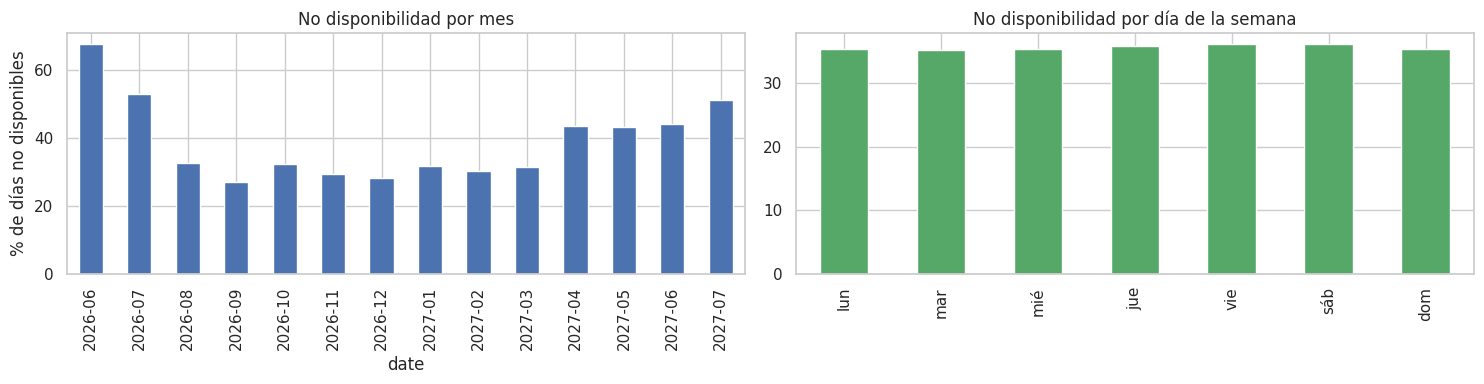

In [22]:
cal["no_disp"] = (cal["available"] == "f")
print(f"% de días NO disponibles (reservados o bloqueados): {cal['no_disp'].mean():.1%}")

mensual = cal.groupby(cal["date"].dt.to_period("M"))["no_disp"].mean()
semanal = cal.groupby(cal["date"].dt.dayofweek)["no_disp"].mean()

fig, ax = plt.subplots(1, 2, figsize=(15, 4))
(mensual*100).plot.bar(ax=ax[0], color="#4c72b0"); ax[0].set_ylabel("% de días no disponibles"); ax[0].set_title("No disponibilidad por mes")
semanal.index = ["lun","mar","mié","jue","vie","sáb","dom"]
(semanal*100).plot.bar(ax=ax[1], color="#55a868"); ax[1].set_title("No disponibilidad por día de la semana")
plt.tight_layout(); plt.show()

**Lectura:** la no disponibilidad es alta en los primeros meses (más cercanos al scrape) y baja en los meses lejanos. Es un patrón típico: **el calendario lejano está más abierto porque todavía no se reservó**, y se observa un repunte hacia mediados de 2027. Esto significa que el calendario **no mide ocupación real**, y los últimos meses están sesgados.

In [23]:
# Consistencia entre listings y calendar: availability_30 vs días disponibles en los primeros 30 días del calendario
inicio = cal.groupby("listing_id")["date"].transform("min")
primeros30 = cal[(cal["date"] - inicio).dt.days < 30]
disp30 = primeros30.assign(d=(primeros30["available"]=="t")).groupby("listing_id")["d"].sum()
cmp = listings.set_index("id")["availability_30"].to_frame().join(disp30.rename("cal_30"))
print("Coincidencia exacta availability_30 (listings) vs calendario:", f"{(cmp['availability_30']==cmp['cal_30']).mean():.1%}")
print("Diferencia absoluta media (días):", (cmp['availability_30']-cmp['cal_30']).abs().mean().round(2))

Coincidencia exacta availability_30 (listings) vs calendario: 100.0%
Diferencia absoluta media (días): 0.0


In [24]:
print("minimum_nights en el calendario:")
print(cal["minimum_nights"].describe(percentiles=[.5,.9,.99]).round(1))
# ¿cambia la regla de noches mínimas dentro de una misma publicación?
var = cal.groupby("listing_id")["minimum_nights"].nunique()
print(f"\nPublicaciones cuya regla de minimum_nights varía durante el año: {(var>1).mean():.1%}")

minimum_nights en el calendario:
count   10,835,026.00
mean             5.50
std             18.90
min              1.00
50%              2.00
90%              7.00
99%             60.00
max            730.00
Name: minimum_nights, dtype: float64



Publicaciones cuya regla de minimum_nights varía durante el año: 20.0%


## 6. Conclusiones, limitaciones y próximos pasos

**Hallazgos principales**
- Los datos provienen con alta probabilidad de **Inside Airbnb** (scraping público, no datos oficiales de Airbnb), son de **Buenos Aires**, con precios en **ARS**, y corresponden a una **foto de fin de junio / principios de julio de 2026**.
- `listings.csv` tiene **~29,7 mil publicaciones y 90 columnas**; `calendar.csv` tiene **~10,8 millones de filas** (365 días por publicación) y está completo y sin duplicados.
- **15 columnas no figuran en el diccionario v4.3** y **13 columnas están 100 % vacías**.
- **Precio:** muy asimétrico (media ≈ 2,7 veces la mediana), con valores extremos (hasta ~171 M ARS/noche) que parecen errores de carga. Trabajar con mediana o log.
- La oferta está **concentrada en pocos barrios** (Palermo y Recoleta suman ≈ 46,5 %) y es **≈ 90 % alojamiento entero**.
- Una parte importante de la oferta es de **hosts multipropiedad** (≈ 64 % de las publicaciones son de hosts con 2 o más).
- El calendario es **consistente con `listings.csv`** (`availability_30` coincide al 100 %), pero en ≈ 20 % de las publicaciones la regla de `minimum_nights` cambia a lo largo del año.
- Los puntajes de reseñas están **pegados a 5**: discriminan poco.

**Limitaciones**
- Es una foto, no una serie temporal. El precio es el publicado, no el efectivamente pagado.
- Disponibilidad ≠ ocupación; la ocupación y los ingresos estimados salen de un modelo con supuestos (tomados de otra ciudad).
- Moneda con alta inflación: cuidado al comparar con otros períodos.

**Próximos pasos sugeridos**
1. Definir y justificar un criterio de exclusión de outliers de precio (por ejemplo, percentiles o revisión manual de los extremos).
2. Decidir el tratamiento de nulos en `bedrooms`, `beds`, `bathrooms` y `price`.
3. Extraer variables de `amenities` (viene como JSON/texto) y de `bathrooms_text`.
4. Plantear la pregunta de análisis (por ejemplo: ¿qué determina el precio?) y modelarla.